In [1]:
import numpy as np
import matplotlib.pyplot as plt
import json

plt.style.use("plot_style.mplstyle")
plt.rc('text', usetex=True)

from pathlib import Path

FALLBACK_DIR = Path("/Users/mchau/mesa_tutorial/PerTDE/Relativistic/Fallback_Data")

In [2]:
adden = "RGB3SM_logR1p0-m1_rp150" 

with open(FALLBACK_DIR / f"rel_p_e_{adden}_a0p2.txt", "r") as f:
    rel_p_E = {k: np.array(v) for k, v in json.load(f).items()}
with open(FALLBACK_DIR / f"rel_p_t_{adden}_a0p2.txt", "r") as f:
    rel_p_T = {k: np.array(v) for k, v in json.load(f).items()}

with open(FALLBACK_DIR / f"rel_r_e_{adden}_a0p2.txt", "r") as f:
    rel_r_E = {k: np.array(v) for k, v in json.load(f).items()}
with open(FALLBACK_DIR / f"rel_r_t_{adden}_a0p2.txt", "r") as f:
    rel_r_T = {k: np.array(v) for k, v in json.load(f).items()}

with open(FALLBACK_DIR / f"rel_sch_e_{adden}.txt", "r") as f:
    rel_sch_E = {k: np.array(v) for k, v in json.load(f).items()}
with open(FALLBACK_DIR / f"rel_sch_t_{adden}.txt", "r") as f:
    rel_sch_T = {k: np.array(v) for k, v in json.load(f).items()}

adden = "RGB3SM_logR1p0-m1_rp150"

with open(FALLBACK_DIR / f"n_e_{adden}.txt", "r") as f:
    n_E = {k: np.array(v) for k, v in json.load(f).items()}
with open(FALLBACK_DIR / f"n_t_{adden}.txt", "r") as f:
    n_T = {k: np.array(v) for k, v in json.load(f).items()}

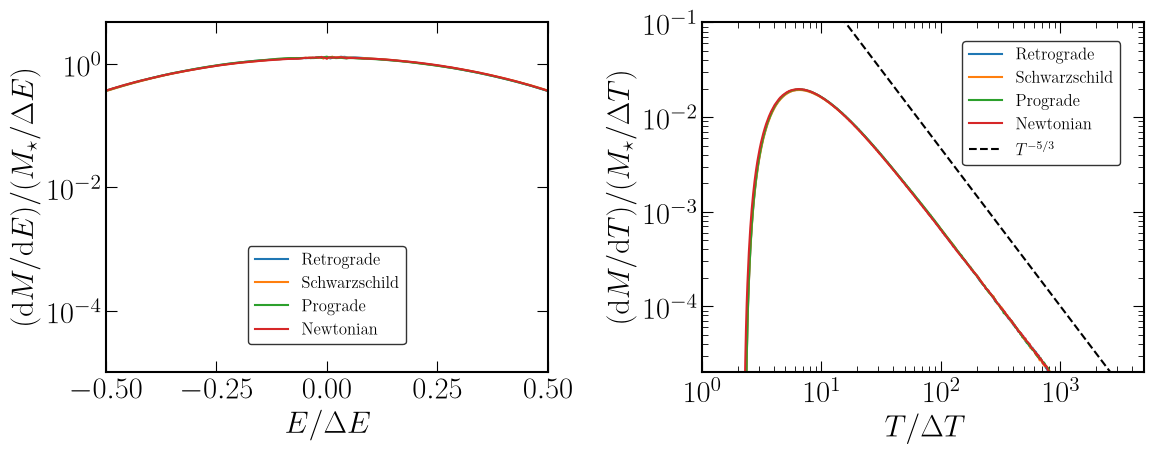

In [12]:
# Build dicts

# Plot
fig, (axE, axT) = plt.subplots(1, 2, figsize=(12, 5))

# Energy
bins_E = np.linspace(-2, 2, 200)
axE.plot(rel_r_E["x"], rel_r_E["y"], label="Retrograde")
axE.plot(rel_sch_E["x"], rel_sch_E["y"], label="Schwarzschild")
axE.plot(rel_p_E["x"], rel_p_E["y"], label="Prograde")
axE.plot(n_E["x"],   n_E["y"],   label="Newtonian")

axE.set_yscale('log')
axE.set_xlabel(r'$E / \Delta E$')
axE.set_ylabel(r'$(\mathrm{d}M/\mathrm{d}E) / (M_\star / \Delta E)$')
axE.set_xlim(-0.5,0.5)
axE.set_ylim(1e-5)

axE.legend(
    loc='center',            # the point on the legend box to anchor
    bbox_to_anchor=(0.5, 0.22),  
    frameon=True,                  # draw the box
    edgecolor='black',             # box outline color
    facecolor='white',             
    fontsize=12
)

# Period
axT.plot(rel_r_T["x"], rel_r_T["y"], label="Retrograde")
axT.plot(rel_sch_T["x"], rel_sch_T["y"], label="Schwarzschild")
axT.plot(rel_p_T["x"], rel_p_T["y"], label="Prograde")
axT.plot(n_T["x"],   n_T["y"],   label="Newtonian")

bins_T = np.logspace(0, 6, 200)
axT.plot(bins_T, 10 * bins_T**(-5/3), 'k--', label=r'$T^{-5/3}$')
axT.set_xscale('log')
axT.set_yscale('log')
axT.set_xlabel(r'$T / \Delta T$')
axT.set_ylabel(r'$(\mathrm{d}M/\mathrm{d}T) / (M_\star / \Delta T)$')
axT.set_xlim(1,5000)
axT.set_ylim(2e-5,0.1)
axT.legend(
    loc='upper left',            # the point on the legend box to anchor
    bbox_to_anchor=(0.57, 0.97),  
    frameon=True,                  # draw the box
    edgecolor='black',             # box outline color
    facecolor='white',             
    fontsize=12
)

plt.tight_layout()
plt.show()

T range: 933.2120808050787 to 993132.9230656415
Fallback-rate range: 7.735622702784904e-12 to 4.751503450471108e-05


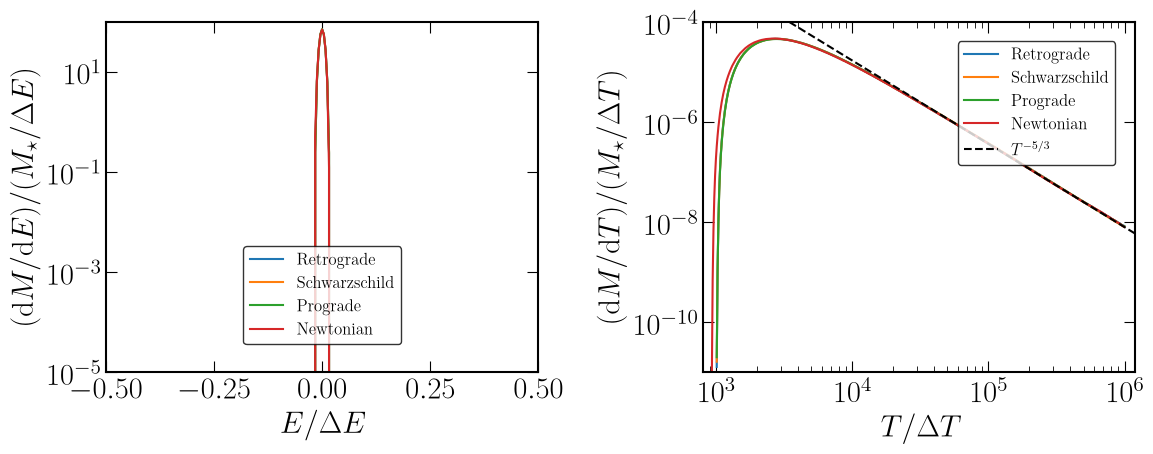

In [16]:
import numpy as np
import matplotlib.pyplot as plt


# ==================================================
# Helper function
# ==================================================

def valid_xy(data):
    x = np.asarray(data["x"], dtype=float)
    y = np.asarray(data["y"], dtype=float)

    mask = (
        np.isfinite(x)
        & np.isfinite(y)
        & (x > 0)
        & (y > 0)
    )

    return x[mask], y[mask]


# ==================================================
# Clean fallback-rate data
# ==================================================

rT_x, rT_y = valid_xy(rel_r_T)
schT_x, schT_y = valid_xy(rel_sch_T)
pT_x, pT_y = valid_xy(rel_p_T)
nT_x, nT_y = valid_xy(n_T)


# ==================================================
# Print data ranges
# ==================================================

all_T = np.concatenate([
    rT_x,
    schT_x,
    pT_x,
    nT_x
])

all_y = np.concatenate([
    rT_y,
    schT_y,
    pT_y,
    nT_y
])

print("T range:", np.min(all_T), "to", np.max(all_T))
print("Fallback-rate range:", np.min(all_y), "to", np.max(all_y))


# ==================================================
# Create figure
# ==================================================

fig, (axE, axT) = plt.subplots(
    1,
    2,
    figsize=(12, 5)
)


# ==================================================
# LEFT PANEL: ENERGY DISTRIBUTION
# ==================================================

axE.plot(
    rel_r_E["x"],
    rel_r_E["y"],
    label="Retrograde"
)

axE.plot(
    rel_sch_E["x"],
    rel_sch_E["y"],
    label="Schwarzschild"
)

axE.plot(
    rel_p_E["x"],
    rel_p_E["y"],
    label="Prograde"
)

axE.plot(
    n_E["x"],
    n_E["y"],
    label="Newtonian"
)


# Log y-axis
axE.set_yscale("log")


# Labels
axE.set_xlabel(r"$E / \Delta E$")
axE.set_ylabel(
    r"$(\mathrm{d}M/\mathrm{d}E) / (M_\star / \Delta E)$"
)


# Limits
axE.set_xlim(-0.5, 0.5)
axE.set_ylim(1e-5, None)


# Legend
axE.legend(
    loc="center",
    bbox_to_anchor=(0.5, 0.22),
    frameon=True,
    edgecolor="black",
    facecolor="white",
    fontsize=12
)


# ==================================================
# RIGHT PANEL: FALLBACK RATE
# ==================================================

axT.plot(
    rT_x,
    rT_y,
    label="Retrograde"
)

axT.plot(
    schT_x,
    schT_y,
    label="Schwarzschild"
)

axT.plot(
    pT_x,
    pT_y,
    label="Prograde"
)

axT.plot(
    nT_x,
    nT_y,
    label="Newtonian"
)


# Log-log axes
axT.set_xscale("log")
axT.set_yscale("log")


# Labels
axT.set_xlabel(r"$T / \Delta T$")
axT.set_ylabel(
    r"$(\mathrm{d}M/\mathrm{d}T) / (M_\star / \Delta T)$"
)


# Limits
axT.set_xlim(800, 1.2e6)
axT.set_ylim(1e-11, 1e-4)


# ==================================================
# T^(-5/3) REFERENCE LINE
# ==================================================

# Choose a point in the late-time fallback regime
T_ref = 1e5


# Find the Newtonian data point closest to T_ref
idx = np.argmin(np.abs(nT_x - T_ref))

y_ref = nT_y[idx]


# Generate reference-line x values
bins_T = np.logspace(
    np.log10(800),
    np.log10(1.2e6),
    300
)


# Normalize the reference line to the Newtonian
# fallback rate at T_ref
reference = y_ref * (bins_T / T_ref)**(-5/3)


# Plot reference line
axT.plot(
    bins_T,
    reference,
    "k--",
    label=r"$T^{-5/3}$"
)


# ==================================================
# RIGHT-PANEL LEGEND
# ==================================================

axT.legend(
    loc="upper left",
    bbox_to_anchor=(0.57, 0.97),
    frameon=True,
    edgecolor="black",
    facecolor="white",
    fontsize=12
)


# ==================================================
# FINAL FORMATTING
# ==================================================

plt.tight_layout()
plt.show()